# External Validation - اختبار Stage 1 على داتاست خارجية واحدة (AI-Leprosy / Roboflow فقط)

## الهدف
اختبار موديل Stage 1 (Ensemble) على بيانات **من مصدر مختلف تمامًا** عن بيانات
التدريب (Atlas Dermatology + ISIC)، عشان نتأكد إن الموديل اتعلم فعلاً أنماط
الجذام الحقيقية مش خصائص مرتبطة بمصدر الصور بس.

## ⚠️ تنويه منهجي (لازم يُذكر في البحث)
داتاست AI-Leprosy من Roboflow **مرفوعة من حساب شخصي غير موثق طبيًا رسميًا**
(مش مؤسسة أكاديمية أو طبية معروفة)، فالنتيجة هنا لازم تُوصف في البحث كـ
"اختبار تعميم غير رسمي (informal generalization stress test)"، مش
benchmark علمي معتمد بمستوى AI4Leprosy.

## المنهجية
- **الصور بالكامل من غير قص** (زي ما اتفقنا - نفس طريقة التدريب بالظبط)
- **دمج train/test/valid** بتاعة الداتاست الخارجية في مجموعة اختبار واحدة
  (إحنا مش بندرب عليها، فتقسيمهم الأصلي مالوش داعي نحترمه)
- **تأكيد إضافي (Cross-check)** من ملفات COCO annotations لو موجودة، عشان
  نتأكد إن اسم الفولدر (lep/not lep) مطابق فعلاً لتصنيف الـ annotation


## 1) تركيب المكتبات

In [ ]:
!pip install -q torch torchvision pillow pandas matplotlib seaborn scikit-learn

## 2) ربط Google Drive
(ارفعي فولدر `AI-Leprosy.v1i.coco` على Drive الأول قبل ما تكمّلي)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3) الإعدادات
عدّلي `EXTERNAL_DATASET_DIR` ليدل على مكان فولدر `AI-Leprosy.v1i.coco` بعد رفعه على Drive.

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/skin_disease_project"

# ---- Stage 1 checkpoints (نفس موديلات Stage 1 المدربة) ----
STAGE1_CHECKPOINTS = {
    "efficientnet_b3": os.path.join(PROJECT_DIR, "outputs/checkpoints/efficientnet_b3_best.pt"),
    "convnext_tiny":   os.path.join(PROJECT_DIR, "outputs/checkpoints/convnext_tiny_best.pt"),
    "resnet50":        os.path.join(PROJECT_DIR, "outputs/checkpoints/resnet50_best.pt"),
}
STAGE1_CLASSES = ["leprosy", "non_leprosy"]

IMAGE_SIZE = 300
DROPOUT_RATE = 0.4

# ---- الداتاست الخارجية (عدّلي المسار ده) ----
EXTERNAL_DATASET_DIR = "/content/drive/MyDrive/AI-Leprosy.v1i.coco"
SPLITS = ["test", "valid"]  # تم استبعاد train: صور الـ train في مجموعات Roboflow بتبقى augmented (نسخ متعددة لنفس الصورة الأصلية)
                              # ده مش leakage من تدريب Stage1 (الداتاست دي أصلًا خارجية تمامًا) لكنه pseudo-replication
                              # هيضخم العينة بنسخ مترابطة مش مستقلة إحصائيًا ويأثر على المقاييس

# ---- تسمية الفولدرات في الداتاست الخارجية (مطابقة للأسماء الحقيقية الفعلية) ----
EXTERNAL_LEP_FOLDER = "leprosy"
EXTERNAL_NONLEP_FOLDER = "non_leprosy"

# ---- مكان حفظ نتائج الـ External Validation ----
EXT_RESULTS_DIR = os.path.join(PROJECT_DIR, "external_validation_results")
os.makedirs(EXT_RESULTS_DIR, exist_ok=True)

print("الإعدادات جاهزة ✅")
print(f"الداتاست الخارجية موجودة؟ {os.path.exists(EXTERNAL_DATASET_DIR)}")


الإعدادات جاهزة ✅
الداتاست الخارجية موجودة؟ True


## 4) تجميع صور الداتاست الخارجية + تأكيد الـ Labels من COCO annotations (لو موجودة)

الكود بيدور على ملف `_annotations.coco.json` في **مكانين محتملين**:
- جوه كل فولدر split مباشرة (`train/_annotations.coco.json`)
- جوه فولدر الكلاس نفسه (`train/lep/_annotations.coco.json`)

لو لقى الملف، بيقارن تصنيف الـ annotation مع اسم الفولدر، وبيطبعلك أي تعارض.
لو مالقاش، بيكمل بس بالاعتماد على اسم الفولدر (أساسي وكافي للتقييم).

In [ ]:
import json
from collections import defaultdict

VALID_EXTS = (".jpg", ".jpeg", ".png", ".bmp")


def find_coco_json(split_dir, class_dir):
    """يدور على ملف الـ annotations في المكانين المحتملين."""
    candidates = [
        os.path.join(split_dir, "_annotations.coco.json"),
        os.path.join(class_dir, "_annotations.coco.json"),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    return None


def load_coco_labels(json_path):
    """يرجع dict: {اسم_الملف: اسم_الكلاس} من ملف COCO."""
    with open(json_path) as f:
        coco = json.load(f)
    cat_id_to_name = {c["id"]: c["name"] for c in coco.get("categories", [])}
    img_id_to_file = {img["id"]: img["file_name"] for img in coco.get("images", [])}

    file_to_label = {}
    for ann in coco.get("annotations", []):
        fname = os.path.basename(img_id_to_file.get(ann["image_id"], ""))
        cat_name = cat_id_to_name.get(ann["category_id"], "unknown")
        file_to_label[fname] = cat_name
    return file_to_label


external_samples = []  # list of dicts: {path, folder_label, coco_label(optional)}
mismatch_count = 0
coco_found_count = 0
excluded_samples = []  # الصور المتعارضة (فولدر != COCO annotation) - بتتستبعد من الحساب

for split in SPLITS:
    split_dir = os.path.join(EXTERNAL_DATASET_DIR, split)
    if not os.path.exists(split_dir):
        print(f"⚠️  فولدر {split} مش موجود - هيتخطى.")
        continue

    for class_folder, label in [(EXTERNAL_LEP_FOLDER, "leprosy"), (EXTERNAL_NONLEP_FOLDER, "non_leprosy")]:
        class_dir = os.path.join(split_dir, class_folder)
        if not os.path.exists(class_dir):
            print(f"⚠️  {split}/{class_folder} مش موجود - هيتخطى.")
            continue

        coco_path = find_coco_json(split_dir, class_dir)
        coco_labels = {}
        if coco_path:
            coco_found_count += 1
            coco_labels = load_coco_labels(coco_path)

        for fname in os.listdir(class_dir):
            if not fname.lower().endswith(VALID_EXTS):
                continue
            fpath = os.path.join(class_dir, fname)
            coco_label = coco_labels.get(fname)

            excluded = False
            if coco_label is not None:
                coco_label_norm = "leprosy" if "not" not in coco_label.lower() and "non" not in coco_label.lower() else "non_leprosy"
                if coco_label_norm != label:
                    mismatch_count += 1
                    excluded = True
                    excluded_samples.append({"path": fpath, "folder_label": label, "coco_label": coco_label})
                    print(f"   ⚠️  تعارض (هيتستبعد): {fpath} - الفولدر يقول '{label}' لكن COCO annotation يقول '{coco_label}'")

            if not excluded:
                external_samples.append({"path": fpath, "label": label, "split": split})

print("\n" + "=" * 70)
print(f"إجمالي صور الداتاست الخارجية المجمّعة (بعد استبعاد التعارضات): {len(external_samples)}")
print(f"عدد ملفات COCO annotations اللي اتلقت: {coco_found_count}")
print(f"عدد الصور المتعارضة اللي اتستبعدت: {mismatch_count}")
print("=" * 70)

label_counts = defaultdict(int)
for s in external_samples:
    label_counts[s["label"]] += 1
print(f"leprosy: {label_counts['leprosy']} صورة")
print(f"non_leprosy: {label_counts['non_leprosy']} صورة")

if mismatch_count > 0:
    print(f"\n⚠️  اتستبعدت {mismatch_count} صورة لأن اسم الفولدر بيتعارض مع COCO annotation "
          "(القرار اتاخد موضوعيًا بدون افتراض إن أحد المصدرين صح). التفاصيل في excluded_samples.")


   ⚠️  تعارض (هيتستبعد): /content/drive/MyDrive/AI-Leprosy.v1i.coco/test/leprosy/Non-Leprosy-02_jpg.rf.dae3f25462a0d4371e7009b4f831fb88.jpg - الفولدر يقول 'leprosy' لكن COCO annotation يقول 'Non Lep'
   ⚠️  تعارض (هيتستبعد): /content/drive/MyDrive/AI-Leprosy.v1i.coco/valid/leprosy/Non-Leprosy_jpg.rf.5739e93b76ce77fb52f45007efb98e04.jpg - الفولدر يقول 'leprosy' لكن COCO annotation يقول 'Non Lep'

إجمالي صور الداتاست الخارجية المجمّعة (بعد استبعاد التعارضات): 120
عدد ملفات COCO annotations اللي اتلقت: 4
عدد الصور المتعارضة اللي اتستبعدت: 2
leprosy: 90 صورة
non_leprosy: 30 صورة

⚠️  اتستبعدت 2 صورة لأن اسم الفولدر بيتعارض مع COCO annotation (القرار اتاخد موضوعيًا بدون افتراض إن أحد المصدرين صح). التفاصيل في excluded_samples.


## 4.5) إزالة النسخ الـ augmented المتكررة (Roboflow dedup)

أسماء الملفات في تصدير Roboflow بالشكل ده:
`Non-Leprosy-06_jpg.rf.384b5d5290bd2adc3984e8502237cbc3.jpg`
بتتكون من: **اسم الصورة الأصلية** + `_jpg.rf.` + hash عشوائي لكل augmentation.
يعني ممكن نفس الصورة الأصلية تتكرر عدة مرات (rotation/flip/brightness) بأسماء
مختلفة ظاهريًا لكنها مش عينات مستقلة إحصائيًا. لو سبناها زي ما هي، أي مقياس
(accuracy, F1..) هيتحسب على عينات مترابطة (pseudo-replicated) مش عينة عشوائية
حقيقية من مرضى/حالات مختلفة، وده بيضخم أو بيشوّه الدقة الحقيقية.

الخطوة دي بتاخد نسخة واحدة بس من كل صورة أصلية (أول ملف تلاقيه لكل base name).

In [ ]:
import re

ROBOFLOW_SUFFIX_RE = re.compile(r"_(jpg|jpeg|png|bmp)\.rf\.[0-9a-fA-F]+", re.IGNORECASE)


def base_image_id(fname):
    """يشيل الـ Roboflow augmentation hash عشان نرجع لاسم الصورة الأصلية."""
    name = os.path.splitext(fname)[0]
    name = ROBOFLOW_SUFFIX_RE.sub("", name)
    return name.lower()


seen_base_ids = set()
deduped_samples = []
duplicates_removed = 0

for s in external_samples:
    bid = base_image_id(os.path.basename(s["path"]))
    key = (bid, s["label"])
    if key in seen_base_ids:
        duplicates_removed += 1
        continue
    seen_base_ids.add(key)
    deduped_samples.append(s)

print(f"عدد الصور قبل الـ dedup: {len(external_samples)}")
print(f"عدد النسخ المكررة (augmented) اللي اتشالت: {duplicates_removed}")
print(f"عدد الصور المستقلة (unique) بعد الـ dedup: {len(deduped_samples)}")

dedup_label_counts = defaultdict(int)
for s in deduped_samples:
    dedup_label_counts[s["label"]] += 1
print(f"leprosy (unique): {dedup_label_counts['leprosy']} صورة")
print(f"non_leprosy (unique): {dedup_label_counts['non_leprosy']} صورة")

if len(deduped_samples) < 30:
    print("\n⚠️  العدد النهائي بعد الـ dedup صغير جدًا - النتائج هتكون مؤشر تقريبي"
          " مش تقييم إحصائي قوي. لازم يتذكر في حدود البحث (limitations).")

external_samples = deduped_samples  # نكمل بيها في باقي النوتبوك


عدد الصور قبل الـ dedup: 120
عدد النسخ المكررة (augmented) اللي اتشالت: 0
عدد الصور المستقلة (unique) بعد الـ dedup: 120
leprosy (unique): 90 صورة
non_leprosy (unique): 30 صورة


## 5) بناء معماريات Stage 1 وتحميل الأوزان المدربة

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image

def get_device():
    return torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

DEVICE = get_device()
print(f"الجهاز: {DEVICE}")


def build_stage1_model(arch_name):
    if arch_name == "efficientnet_b3":
        model = models.efficientnet_b3(weights=None)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(p=DROPOUT_RATE), nn.Linear(in_features, 2))
    elif arch_name == "convnext_tiny":
        model = models.convnext_tiny(weights=None)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(nn.Dropout(p=DROPOUT_RATE), nn.Linear(in_features, 2))
    elif arch_name == "resnet50":
        model = models.resnet50(weights=None)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(p=DROPOUT_RATE), nn.Linear(in_features, 2))
    else:
        raise ValueError(arch_name)
    return model


stage1_models = {}
for name, path in STAGE1_CHECKPOINTS.items():
    if not os.path.exists(path):
        print(f"❌ {name}: checkpoint مش موجود في {path}")
        continue
    model = build_stage1_model(name)
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    model.to(DEVICE)
    model.eval()
    stage1_models[name] = model
    print(f"✅ تم تحميل {name}")

print(f"\nعدد الموديلات المحمّلة: {len(stage1_models)} / 3")


الجهاز: cuda
✅ تم تحميل efficientnet_b3
✅ تم تحميل convnext_tiny
✅ تم تحميل resnet50

عدد الموديلات المحمّلة: 3 / 3


## 6) تشغيل الـ Ensemble على كل صور الداتاست الخارجية (صور كاملة، من غير قص)

In [ ]:
import torch.nn.functional as F
import numpy as np
from tqdm.notebook import tqdm

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

inference_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),   # نفس المعالجة بالظبط المستخدمة وقت التدريب
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

leprosy_idx = STAGE1_CLASSES.index("leprosy")

all_probs = []
all_true_labels = []
failed_images = []

for sample in tqdm(external_samples, desc="جاري التقييم"):
    try:
        img = Image.open(sample["path"]).convert("RGB")
    except Exception as e:
        failed_images.append((sample["path"], str(e)))
        continue

    tensor = inference_transform(img).unsqueeze(0).to(DEVICE)

    model_probs = []
    with torch.no_grad():
        for model in stage1_models.values():
            output = model(tensor)
            probs = F.softmax(output, dim=1).cpu().numpy()[0]
            model_probs.append(probs)

    avg_probs = np.mean(model_probs, axis=0)
    all_probs.append(avg_probs)
    all_true_labels.append(0 if sample["label"] == "leprosy" else 1)  # 0=leprosy, 1=non_leprosy (لازم يطابق STAGE1_CLASSES)

all_probs = np.array(all_probs)
all_true_labels = np.array(all_true_labels)
all_preds = all_probs.argmax(axis=1)

print(f"\nتم تقييم {len(all_probs)} صورة بنجاح.")
if failed_images:
    print(f"⚠️  فشل تحميل {len(failed_images)} صورة (ملفات تالفة على الأرجح).")


جاري التقييم:   0%|          | 0/120 [00:00<?, ?it/s]


تم تقييم 120 صورة بنجاح.


## 7) النتائج: مقارنة أداء External Validation بأداء الاختبار الأصلي

مقارنة: الأداء على بيانات from نفس المصدر مقابل بيانات خارجية
           Metric  Original_Test (In-Distribution)  External_Validation (AI-Leprosy)   Gap
         Accuracy                            97.01                             48.33 48.68
Precision_Leprosy                            87.62                             93.75 -6.13
   Recall_Leprosy                            91.09                             33.33 57.76
       F1_Leprosy                            89.32                             49.18 40.14
              AUC                             0.98                              0.77  0.22


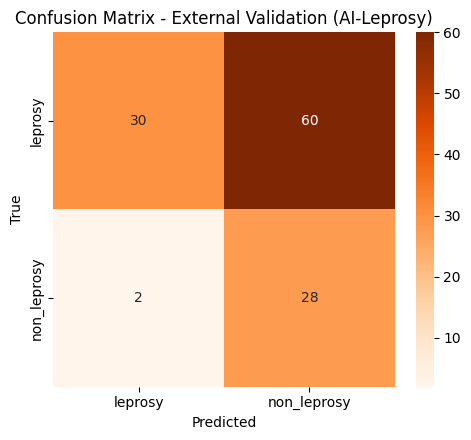

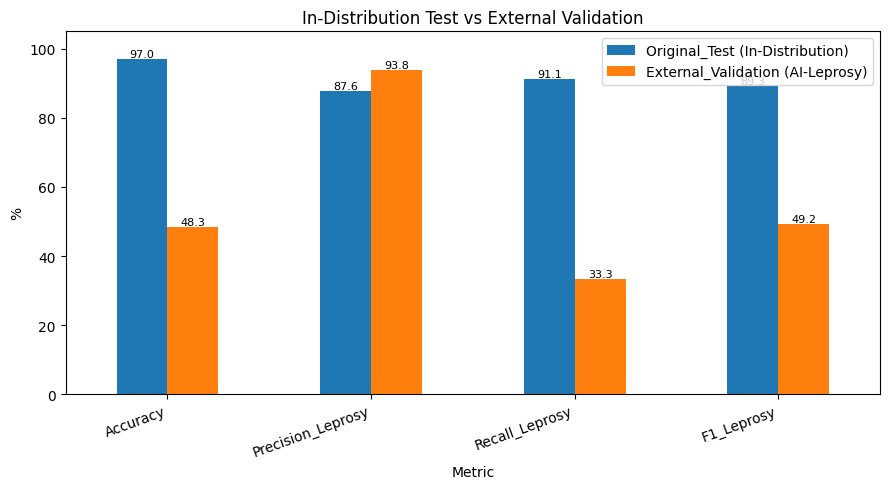


تفسير الفجوة (Generalization Gap):
⚠️  فجوة كبيرة (48.7 نقطة) - الموديل يعاني من ضعف تعميم واضح على بيانات من مصدر مختلف.


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc
)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ---- حساب المقاييس على الداتاست الخارجية ----
ext_accuracy = accuracy_score(all_true_labels, all_preds) * 100
ext_precision = precision_score(all_true_labels, all_preds, pos_label=leprosy_idx, zero_division=0) * 100
ext_recall = recall_score(all_true_labels, all_preds, pos_label=leprosy_idx, zero_division=0) * 100
ext_f1 = f1_score(all_true_labels, all_preds, pos_label=leprosy_idx, zero_division=0) * 100

fpr, tpr, _ = roc_curve(all_true_labels, all_probs[:, leprosy_idx], pos_label=leprosy_idx)
ext_auc = auc(fpr, tpr)

# ---- مقارنة بأرقام Stage 1 الأصلية (من نواتج التشغيل الفعلية سابقًا) ----
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision_Leprosy", "Recall_Leprosy", "F1_Leprosy", "AUC"],
    "Original_Test (In-Distribution)": [97.01, 87.62, 91.09, 89.32, 0.981],
    "External_Validation (AI-Leprosy)": [ext_accuracy, ext_precision, ext_recall, ext_f1, ext_auc],
})
comparison_df["Gap"] = comparison_df["Original_Test (In-Distribution)"] - comparison_df["External_Validation (AI-Leprosy)"]

print("=" * 70)
print("مقارنة: الأداء على بيانات from نفس المصدر مقابل بيانات خارجية")
print("=" * 70)
print(comparison_df.round(2).to_string(index=False))

comparison_df.to_csv(os.path.join(EXT_RESULTS_DIR, "external_validation_comparison.csv"), index=False)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_true_labels, all_preds)
plt.figure(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
            xticklabels=STAGE1_CLASSES, yticklabels=STAGE1_CLASSES)
plt.title("Confusion Matrix - External Validation (AI-Leprosy)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(EXT_RESULTS_DIR, "external_confusion_matrix.png"), dpi=150)
plt.show()

# ---- Bar chart مقارنة ----
fig, ax = plt.subplots(figsize=(9, 5))
metrics_only = comparison_df[comparison_df["Metric"] != "AUC"].set_index("Metric")
metrics_only[["Original_Test (In-Distribution)", "External_Validation (AI-Leprosy)"]].plot(kind="bar", ax=ax)
ax.set_ylabel("%"); ax.set_ylim(0, 105)
ax.set_title("In-Distribution Test vs External Validation")
plt.xticks(rotation=20, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(EXT_RESULTS_DIR, "external_vs_original_comparison.png"), dpi=150)
plt.show()

# ---- تفسير الفجوة ----
print("\n" + "=" * 70)
print("تفسير الفجوة (Generalization Gap):")
print("=" * 70)
acc_gap = comparison_df.loc[comparison_df["Metric"] == "Accuracy", "Gap"].values[0]
if acc_gap < 5:
    print(f"✅ فجوة صغيرة جدًا ({acc_gap:.1f} نقطة) - دليل قوي على تعميم جيد للموديل على بيانات من مصدر مختلف.")
elif acc_gap < 15:
    print(f"ℹ️  فجوة متوسطة ({acc_gap:.1f} نقطة) - أداء مقبول لكن فيه انخفاض ملحوظ خارج توزيع بيانات التدريب.")
else:
    print(f"⚠️  فجوة كبيرة ({acc_gap:.1f} نقطة) - الموديل يعاني من ضعف تعميم واضح على بيانات من مصدر مختلف.")


## 8) تحليل الـ Threshold: هل الـ Recall المنخفض بسبب العتبة الافتراضية (0.5)؟

الموديل بيديله احتمالية (probability) لكل صورة، وبعدين بنقارنها بعتبة (threshold)
عشان نقرر "leprosy" ولا لأ - غالبًا العتبة الافتراضية بتكون 0.5. لكن العتبة دي
اتضبطت (implicitly) على توزيع بيانات التدريب (Atlas/ISIC)، ومش لازم تبقى مناسبة
لتوزيع بيانات خارجية زي AI-Leprosy.

هنا بنجرب مجموعة thresholds مختلفة ونشوف: هل فيه threshold تاني يرفع الـ Recall
من غير ما يضرب الـ Precision بشدة؟ ده هيفرق بين تفسيرين مختلفين تمامًا:
- **لو أه**: المشكلة جزء منها في العتبة، مش بس في الموديل نفسه.
- **لو لأ**: المشكلة أعمق (domain shift حقيقي) - الموديل فعلاً مش عارف يميّز
  الجذام في الصور دي، بغض النظر عن العتبة.

تحليل تأثير تغيير الـ Threshold - External Validation
 threshold  precision  recall   f1
       0.0       78.1    98.9 87.3
       0.1       83.1    82.2 82.7
       0.2       86.8    73.3 79.5
       0.2       87.0    66.7 75.5
       0.2       88.7    61.1 72.4
       0.3       90.6    53.3 67.1
       0.4       90.4    52.2 66.2
       0.4       93.0    44.4 60.2
       0.4       93.9    34.4 50.4
       0.5       93.8    33.3 49.2
       0.6       96.3    28.9 44.4
       0.6       95.8    25.6 40.4
       0.6       94.1    17.8 29.9
       0.7       93.8    16.7 28.3
       0.8       91.7    12.2 21.6
       0.8       87.5     7.8 14.3
       0.8       75.0     3.3  6.4
       0.9      100.0     1.1  2.2
       1.0        0.0     0.0  0.0

أفضل threshold حسب Youden's J: 0.23
أفضل threshold حسب أعلى F1: 0.05 (F1=87.3%, Recall=98.9%, Precision=78.1%)


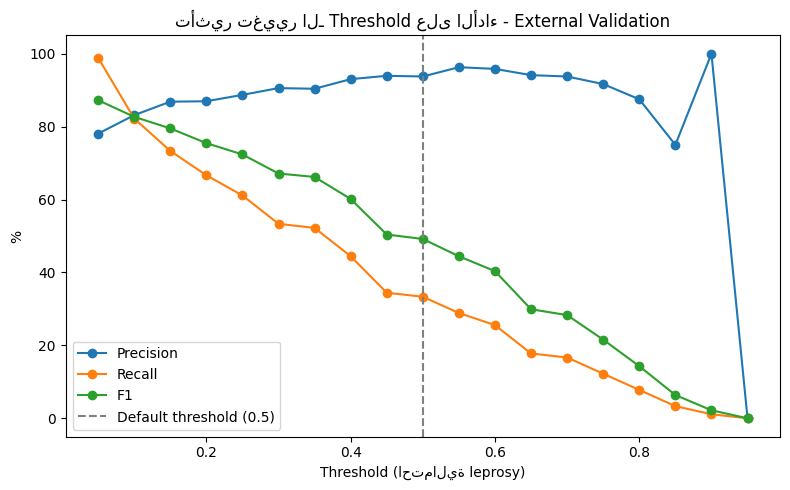


⚠️  تحريك الـ threshold لـ 0.05 بيرفع الـ Recall من 33.3% لـ 98.9% - يبقى جزء من المشكلة هو العتبة الافتراضية مش بس ضعف الموديل، لكن ده مبيلغيش أهمية إعادة معايرة الموديل.


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_curve

print("=" * 70)
print("تحليل تأثير تغيير الـ Threshold - External Validation")
print("=" * 70)

leprosy_probs = all_probs[:, leprosy_idx]
y_true_leprosy = (all_true_labels == leprosy_idx).astype(int)

thresholds_to_test = np.arange(0.05, 0.96, 0.05)
threshold_rows = []
for t in thresholds_to_test:
    preds_t = (leprosy_probs >= t).astype(int)
    prec = precision_score(y_true_leprosy, preds_t, zero_division=0) * 100
    rec = recall_score(y_true_leprosy, preds_t, zero_division=0) * 100
    f1 = f1_score(y_true_leprosy, preds_t, zero_division=0) * 100
    threshold_rows.append({"threshold": round(t, 2), "precision": prec, "recall": rec, "f1": f1})

threshold_df = pd.DataFrame(threshold_rows)
print(threshold_df.round(1).to_string(index=False))

# أفضل threshold حسب Youden's J (بيوازن بين Sensitivity و Specificity)
fpr, tpr, roc_thresholds = roc_curve(y_true_leprosy, leprosy_probs, pos_label=1)
youden_j = tpr - fpr
best_threshold_youden = roc_thresholds[np.argmax(youden_j)]

# أفضل threshold حسب أعلى F1
best_f1_row = threshold_df.loc[threshold_df["f1"].idxmax()]

print(f"\nأفضل threshold حسب Youden's J: {best_threshold_youden:.2f}")
print(f"أفضل threshold حسب أعلى F1: {best_f1_row['threshold']:.2f} "
      f"(F1={best_f1_row['f1']:.1f}%, Recall={best_f1_row['recall']:.1f}%, Precision={best_f1_row['precision']:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
ax.plot(threshold_df["threshold"], threshold_df["recall"], marker="o", label="Recall")
ax.plot(threshold_df["threshold"], threshold_df["f1"], marker="o", label="F1")
ax.axvline(0.5, color="gray", linestyle="--", label="Default threshold (0.5)")
ax.set_xlabel("Threshold (احتمالية leprosy)")
ax.set_ylabel("%")
ax.set_title("تأثير تغيير الـ Threshold على الأداء - External Validation")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(EXT_RESULTS_DIR, "external_threshold_analysis.png"), dpi=150)
plt.show()

print()
if best_f1_row["recall"] - ext_recall > 15:
    print(f"⚠️  تحريك الـ threshold لـ {best_f1_row['threshold']:.2f} بيرفع الـ Recall من "
          f"{ext_recall:.1f}% لـ {best_f1_row['recall']:.1f}% - يبقى جزء من المشكلة هو "
          "العتبة الافتراضية مش بس ضعف الموديل، لكن ده مبيلغيش أهمية إعادة معايرة الموديل.")
else:
    print(f"ℹ️  حتى بعد تجربة كل الـ thresholds، أفضل Recall ممكن الوصول له هو "
          f"{threshold_df['recall'].max():.1f}% - يبقى المشكلة أعمق من العتبة، "
          "والموديل فعلاً بيواجه صعوبة حقيقية مع نمط الصور دي (domain shift).")


## 9) Bootstrap 95% Confidence Intervals

عينة الـ external validation صغيرة نسبيًا (~90-120 صورة)، يعني رقم زي
"Recall = 33.3%" ممكن يكون مداه الحقيقي واسع لو أخدنا عينة تانية بنفس الحجم.
الـ Bootstrap بيدينا فكرة عن **مدى الثقة (Confidence Interval)** حوالين كل
مقياس، عن طريق إعادة أخذ عينات عشوائية (بالإحلال) من نفس النتائج آلاف المرات
وحساب المدى اللي بيقع فيه 95% من القيم.

ده مهم جدًا يتذكر في البحث كـ حدود (limitations) للنتيجة، بدل ما تتقال
الأرقام (زي 33.3% Recall) كأنها قيمة نهائية دقيقة 100%.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("=" * 70)
print("Bootstrap 95% Confidence Intervals (n=1000 resamples)")
print("=" * 70)

n_bootstrap = 1000
rng = np.random.default_rng(42)
n_samples = len(all_true_labels)

boot_metrics = {"accuracy": [], "precision": [], "recall": [], "f1": []}
skipped = 0

for _ in range(n_bootstrap):
    idx = rng.integers(0, n_samples, n_samples)
    yt = all_true_labels[idx]
    yp = all_preds[idx]
    if len(np.unique(yt)) < 2:  # عينة بوتستراب مالهاش تنوع كافي (نادر بس ممكن)
        skipped += 1
        continue
    boot_metrics["accuracy"].append(accuracy_score(yt, yp) * 100)
    boot_metrics["precision"].append(precision_score(yt, yp, pos_label=leprosy_idx, zero_division=0) * 100)
    boot_metrics["recall"].append(recall_score(yt, yp, pos_label=leprosy_idx, zero_division=0) * 100)
    boot_metrics["f1"].append(f1_score(yt, yp, pos_label=leprosy_idx, zero_division=0) * 100)

point_estimates = {"accuracy": ext_accuracy, "precision": ext_precision, "recall": ext_recall, "f1": ext_f1}

ci_rows = []
for name, vals in boot_metrics.items():
    vals = np.array(vals)
    lower, upper = np.percentile(vals, [2.5, 97.5])
    ci_rows.append({
        "Metric": name,
        "Estimate": point_estimates[name],
        "CI_lower_95": lower,
        "CI_upper_95": upper,
    })

ci_df = pd.DataFrame(ci_rows)
print(ci_df.round(1).to_string(index=False))
ci_df.to_csv(os.path.join(EXT_RESULTS_DIR, "external_bootstrap_ci.csv"), index=False)

if skipped:
    print(f"\n(اتشال {skipped} عينة bootstrap من {n_bootstrap} لعدم تنوع كافي - عادي وطبيعي.)")

print(f"\nملاحظة: العينة صغيرة نسبيًا (n={n_samples})، فمدى الـ CI متوقع يكون واسع.")
print("لازم يتذكر في البحث إن الأرقام دي تقديرية بحدود ثقة واسعة مش أرقام نهائية دقيقة.")


Bootstrap 95% Confidence Intervals (n=1000 resamples)
   Metric  Estimate  CI_lower_95  CI_upper_95
 accuracy      48.3         39.1         57.5
precision      93.8         83.9        100.0
   recall      33.3         24.2         43.4
       f1      49.2         38.1         60.0

ملاحظة: العينة صغيرة نسبيًا (n=120)، فمدى الـ CI متوقع يكون واسع.
لازم يتذكر في البحث إن الأرقام دي تقديرية بحدود ثقة واسعة مش أرقام نهائية دقيقة.


## 10) مقاييس إضافية للورقة (Specificity / Balanced accuracy / AUC مع CI / baseline)

لأن نسبة الجذام في Roboflow (75%) أعلى بكتير من بيانات التدريب (13.7%)، الـ accuracy والـ precision والـ F1 بتتأثر بنسبة الـ prevalence. عشان كده بنضيف مقاييس مش بتتأثر بيها: **Specificity** و**Balanced accuracy** و**AUC**، وبنقارن الـ F1 بـ baseline "كل الصور جذام".

الـ thresholds اللي تحت (0.170 و 0.345) **محسوبة من الـ validation الداخلي** (مش من Roboflow)، في نوتبوك `External_Validation_Roboflow` / `Final_Validation_Pack`. لو غيّرتي الموديلات لازم تعيدي حسابها.

In [ ]:
from sklearn.metrics import roc_auc_score

y = (all_true_labels == leprosy_idx).astype(int)          # 1 = leprosy
s = all_probs[:, leprosy_idx]                              # P(leprosy), ensemble
n = len(y); prev = y.mean()

def _m(y, s, t=0.5):
    p = (s >= t).astype(int)
    tp = int(((y == 1) & (p == 1)).sum()); fn = int(((y == 1) & (p == 0)).sum())
    fp = int(((y == 0) & (p == 1)).sum()); tn = int(((y == 0) & (p == 0)).sum())
    rec = 100 * tp / max(tp + fn, 1); spec = 100 * tn / max(tn + fp, 1)
    return dict(tp=tp, fn=fn, fp=fp, tn=tn, rec=rec, spec=spec, bacc=(rec + spec) / 2,
                acc=100 * (tp + tn) / len(y), prec=100 * tp / max(tp + fp, 1))

m = _m(y, s)
rng = np.random.default_rng(42); B = {k: [] for k in ["spec", "bacc", "auc"]}
for _ in range(1000):
    i = rng.integers(0, n, n)
    if len(np.unique(y[i])) < 2: continue
    mi = _m(y[i], s[i]); B["spec"].append(mi["spec"]); B["bacc"].append(mi["bacc"]); B["auc"].append(roc_auc_score(y[i], s[i]))
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in B.items()}
auc_ = roc_auc_score(y, s)
print(f"n={n} | prevalence of leprosy = {100*prev:.0f}%")
print(f"Specificity       : {m['spec']:.1f}%  [{ci['spec'][0]:.1f}, {ci['spec'][1]:.1f}]")
print(f"Balanced accuracy : {m['bacc']:.1f}%  [{ci['bacc'][0]:.1f}, {ci['bacc'][1]:.1f}]")
print(f"AUC               : {auc_:.3f}  [{ci['auc'][0]:.3f}, {ci['auc'][1]:.3f}]")
print(f"All-positive baseline F1 (label everything leprosy): {100*2*prev/(1+prev):.1f}%  vs model F1 {ext_f1:.1f}%")

print("\nThresholds fixed beforehand on the in-distribution VALIDATION set (not tuned on Roboflow):")
for name, t in [("default", 0.5), ("val Youden", 0.170), ("val 95% sensitivity", 0.345)]:
    r = _m(y, s, t); print(f"  {name:20s} thr={t:.3f} | recall {r['rec']:.1f}% | specificity {r['spec']:.1f}% | balanced acc {r['bacc']:.1f}%")
print("\nملاحظة: threshold 0.05 (F1-optimal على Roboflow نفسها) مش مناسب: بيقلّل الـ specificity جدًا، ومتحسبش كنتيجة نظيفة لأنه متضبط على نفس البيانات.")